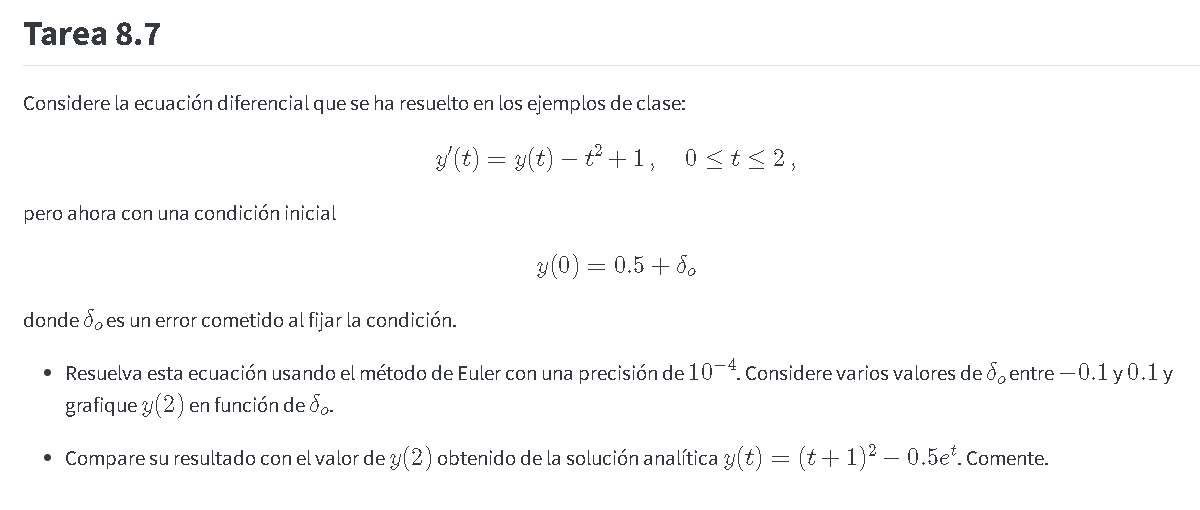

In [ ]:
#tarea 8.7: Metodo de Euler
#ccuacion diferencial: y' = y - t^2 + 1
#condicion inicial: y(0) = 0.5 + delta0

import numpy as np
import matplotlib.pyplot as plt


# definimos el lado derecho de la edo
#para calcular la pendiente en cada paso
def f(t, y):
    return y - t**2 + 1


#el metodo de Euler
#w(i+1) = w(i) + h*f(t(i), w(i))
def euler(f, a, b, y0, N):

    h = (b - a) / N

    ts = np.zeros(N + 1)
    sol = np.zeros(N + 1)

    t, w = a, y0

    for i in range(N):

        # se guarda  la aproximacion antes de avanzar al siguiente paso
        ts[i] = t
        sol[i] = w

        #usamos la pendiente actual para estimar el siguiente valor
        w = w + h * f(t, w)
        t = t + h

    #agregamos el ultimo punto para completar el intervalo hasta t = 2
    ts[N] = t
    sol[N] = w

    return ts, sol


#definimos el intervalo y la precision que nos pide
a, b = 0, 2
precision = 1e-4

#aqui aplicamos la cota de error de Euler, usamos L = 1,
#pq la derivada de f respecto de y es igual a 1
L = 1

#cota para la segunda derivada de la solucion
#consideramos el intervalo de valores de delta0 que analizaremos
M = abs(2 - 0.6 * np.exp(2))

#despejamos el paso maximo a partir de la cota de error
#y asegurarnos de que el error en t = 2 sea menor que la precision
h_max = (2 * L * precision) / (M * (np.exp(L * (b - a)) - 1))

#se elege una cantidad de pasos suficiente para cumplir esa condicion
N = int(np.ceil((b - a) / h_max))
h = (b - a) / N

#y comprobamos cuanto vale la cota de error la eleccion
cota_error = h * M / (2 * L) * (np.exp(L * (b - a)) - 1)

print("N =", N)
print("h =", h)
print("Cota de error en t = 2:", cota_error)


#probamos distintos errores en la condicion inicial,
#desde -0.1 hasta 0.1, para ver como afectan al resultado final
deltas = np.linspace(-0.1, 0.1, 21)

y2_euler = []
y2_exacta = []

for delta in deltas:

    #cada valor de delta modifica la condicion inicial

    y0 = 0.5 + delta

    #Resolvemos nuevamente la ecuacion para cada condicion inicial

    _, sol = euler(f, a, b, y0, N)

    #nos interesa guardar solamente el resultado al llegar a t = 2

    y2_euler.append(sol[-1])

    #calculamos tambien el valor exacto para poder comparar.
    #esta expresion corresponde a la solucion analitica con delta0.

    y2_exacta.append(9 + (delta - 0.5) * np.exp(2))


# Pasamos las listas a arreglos para poder trabajar con sus valores.
y2_euler = np.array(y2_euler)
y2_exacta = np.array(y2_exacta)

# Calculamos la diferencia entre Euler y la solucion exacta
# para cada uno de los errores iniciales.
errores = np.abs(y2_euler - y2_exacta)


# Comparamos los resultados cuando no existe error inicial,
# , cuando delta0 = 0.

indice_cero = np.where(np.isclose(deltas, 0))[0][0]

valor_analitico = 9 - 0.5 * np.exp(2)

print("y(2) analitico para delta0 = 0:", valor_analitico)
print("y(2) con Euler para delta0 = 0:", y2_euler[indice_cero])
print("Error para delta0 = 0:", errores[indice_cero])
print("Mayor error entre todos los delta0:", np.max(errores))


# Graficamos el valor final de la solucion en funcion del error inicial
#para comparar directamente Euler con la solucion exacta
plt.figure(figsize=(8, 5))

plt.plot(deltas, y2_euler, "o", label="Euler")
plt.plot(deltas, y2_exacta, label="Solución exacta con cada delta")

#Linea que representa el valor analitico cuando delta0 = 0
plt.axhline(valor_analitico, linestyle="--",
            label="Solución analítica para delta = 0")

plt.xlabel("Error en la condición inicial (delta 0)")
plt.ylabel("Valor de y(2)")
plt.title("Efecto del error inicial en y(2)")

plt.legend()
plt.grid(True)
plt.show()

## Nota: 6.0

Base: 1/1; funcionamiento: 3/4; comentarios: 1/1; claridad: 1/1.

Falta interpretar la comparación y explicar cómo el error inicial se amplifica en el valor final.
